<a href="https://colab.research.google.com/github/Kavishka2401/GPTea/blob/C_1_Yield_Prediction/Machine_Learning_Pipeline/Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import Google Drive to get the final dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import Libraries
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [ ]:
final_data_path = '/content/drive/MyDrive/DSGP_DOCS/Datasets/Final_Data_Merged.csv'

# Load final data
final_data = pd.read_csv(final_data_path)

In [ ]:
final_data.head()

,Year,Month,YPH,T200,UT925,U709,Epson Salt,Dolomite,Urea,Zinc,...,temperature_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,relative_humidity_2m_mean,precipitation_sum,rain_sum,sunshine_duration,wind_speed_10m_max,wind_speed_10m_mean,et0_fao_evapotranspiration
0,2017,Jan,85,0,4500,0,0,12000,150,0,...,18.412903,93.516129,60.483871,76.903226,201.3,201.3,1037724.72,8.451613,4.516129,3.479032
1,2017,Feb,112,0,0,6500,0,0,0,250,...,18.410714,97.642857,64.357143,83.428571,151.6,151.6,994468.11,7.542857,3.889286,3.722500
2,2017,Mar,135,500,7200,0,80,0,0,0,...,19.248387,98.838710,73.677419,88.451613,221.3,221.3,1113625.83,8.212903,4.074194,3.654516
3,2017,Apr,149,0,9500,2800,0,18500,160,0,...,20.036667,99.533333,77.666667,90.933333,152.5,152.5,1106964.18,9.070000,4.480000,3.620333
4,2017,May,128,0,0,11500,150,0,0,320,...,19.919355,99.741935,84.612903,94.290323,681.7,681.7,807927.15,10.612903,6.793548,2.560968


### Dataset structure

In [ ]:
final_data.shape

(108, 25)

### Data types inspection

In [ ]:
final_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Year                        108 non-null    int64  
 1   Month                       108 non-null    object 
 2   YPH                         108 non-null    int64  
 3   T200                        108 non-null    int64  
 4   UT925                       108 non-null    int64  
 5   U709                        108 non-null    int64  
 6   Epson Salt                  108 non-null    int64  
 7   Dolomite                    108 non-null    int64  
 8   Urea                        108 non-null    int64  
 9   Zinc                        108 non-null    int64  
 10  Compost                     108 non-null    int64  
 11  BioShakthi                  108 non-null    int64  
 12  BioShield                   108 non-null    int64  
 13  temperature_2m_max          108 non

### Missing value matrix

In [ ]:
final_data.isna().sum()

,0
Year,0
Month,0
YPH,0
T200,0
UT925,0
U709,0
Epson Salt,0
Dolomite,0
Urea,0
Zinc,0


In [ ]:
# Check empty columns
rows_with_nan = final_data[final_data.isna().any(axis=1)]
display(rows_with_nan)

,Year,Month,YPH,T200,UT925,U709,Epson Salt,Dolomite,Urea,Zinc,...,temperature_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,relative_humidity_2m_mean,precipitation_sum,rain_sum,sunshine_duration,wind_speed_10m_max,wind_speed_10m_mean,et0_fao_evapotranspiration


**Interpretation**

The dataset consists of 108 rows in total. It has 25 columns which includes year, month, fertilizers and weather data.


## Target Variable

### Descriptive Statistics of YPH

In [ ]:
# Descriptive statistics
yp_stats = final_data['YPH'].describe()
skewness = final_data['YPH'].skew()

print("=== YPH Descriptive Statistics ===")
print(yp_stats)
print(f"Skewness: {skewness:.2f}")

=== YPH Descriptive Statistics ===
count    108.000000
mean     141.944444
std       34.912396
min       72.000000
25%      115.000000
50%      142.000000
75%      165.750000
max      228.000000
Name: YPH, dtype: float64
Skewness: 0.19


### Histogram of YPH

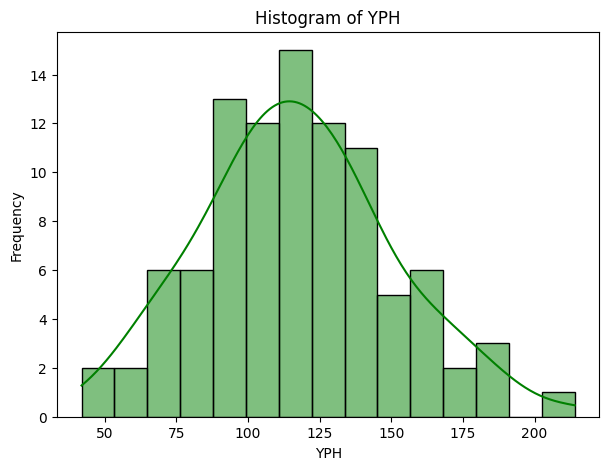

In [ ]:
plt.figure(figsize=(7,5))
sns.histplot(final_data['YPH'], bins=15, kde=True, color='green')
plt.title('Histogram of YPH')
plt.xlabel('YPH')
plt.ylabel('Frequency')
plt.show()

### Boxplot of YPH

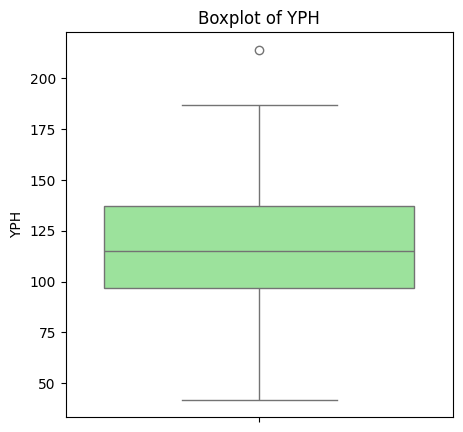

In [ ]:
plt.figure(figsize=(5,5))
sns.boxplot(y=final_data['YPH'], color='lightgreen')
plt.title('Boxplot of YPH')
plt.ylabel('YPH')
plt.show()

### YPH Over Time

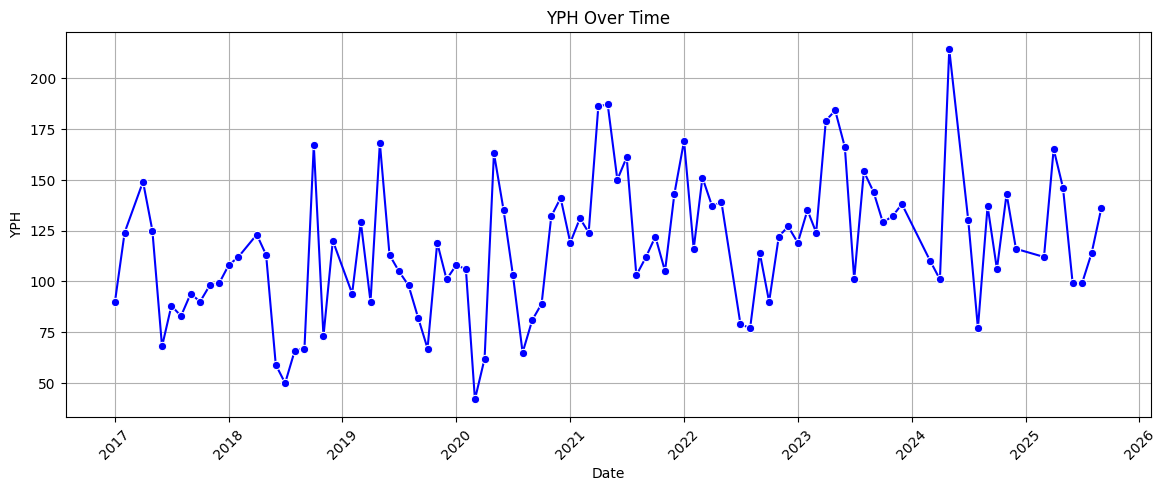

In [ ]:
# Convert Month to numeric
final_data['Month_num'] = final_data['Month'].astype(str).str.zfill(2)  # pad with zero

# Create Date column
final_data['Date'] = pd.to_datetime(final_data['Year'].astype(str) + '-' + final_data['Month_num'] + '-01')

plt.figure(figsize=(14,5))
sns.lineplot(data=final_data, x='Date', y='YPH', marker='o', color='blue')
plt.title('YPH Over Time')
plt.xlabel('Date')
plt.ylabel('YPH')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### Average YPH by Month

/tmp/ipython-input-2855020229.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_avg = final_data.groupby('Month')['YPH'].mean().reset_index()
/tmp/ipython-input-2855020229.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=monthly_avg, x='Month', y='YPH', palette='viridis')


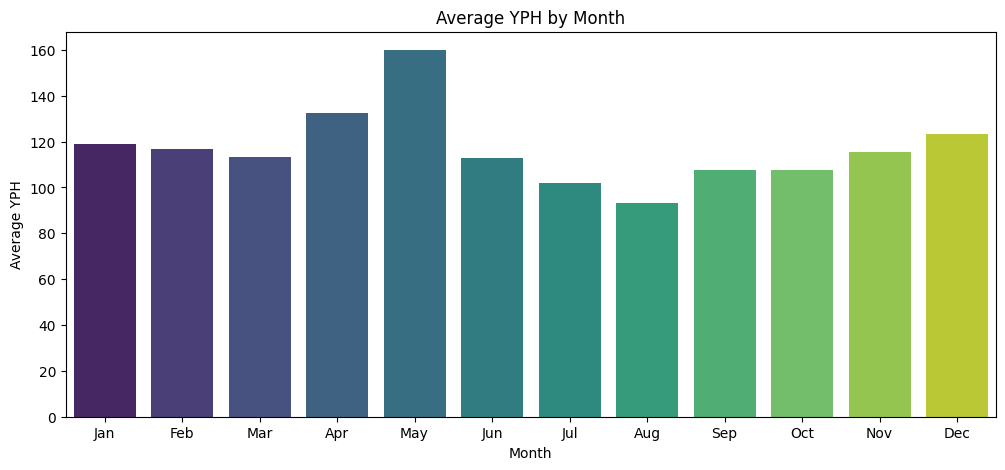

In [ ]:
# Ensure Month is categorical with correct order
months_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
final_data['Month'] = pd.Categorical(final_data['Month'], categories=months_order, ordered=True)

# Compute monthly average YPH
monthly_avg = final_data.groupby('Month')['YPH'].mean().reset_index()

plt.figure(figsize=(12,5))
sns.barplot(data=monthly_avg, x='Month', y='YPH', palette='viridis')
plt.title('Average YPH by Month')
plt.xlabel('Month')
plt.ylabel('Average YPH')
plt.show()

### Yearly Trend of YPH

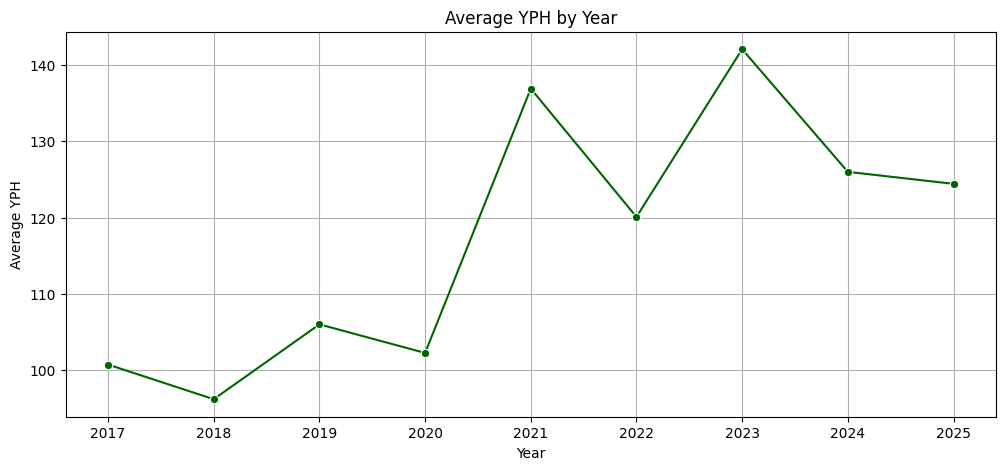

In [ ]:
# Compute yearly average YPH
yearly_avg = final_data.groupby('Year')['YPH'].mean().reset_index()

plt.figure(figsize=(12,5))
sns.lineplot(data=yearly_avg, x='Year', y='YPH', marker='o', color='darkgreen')
plt.title('Average YPH by Year')
plt.xlabel('Year')
plt.ylabel('Average YPH')
plt.grid(True)
plt.show()

### Monthly Boxplot (Seasonality & Variability)

/tmp/ipython-input-2158770010.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=final_data, x='Month', y='YPH', palette='coolwarm')


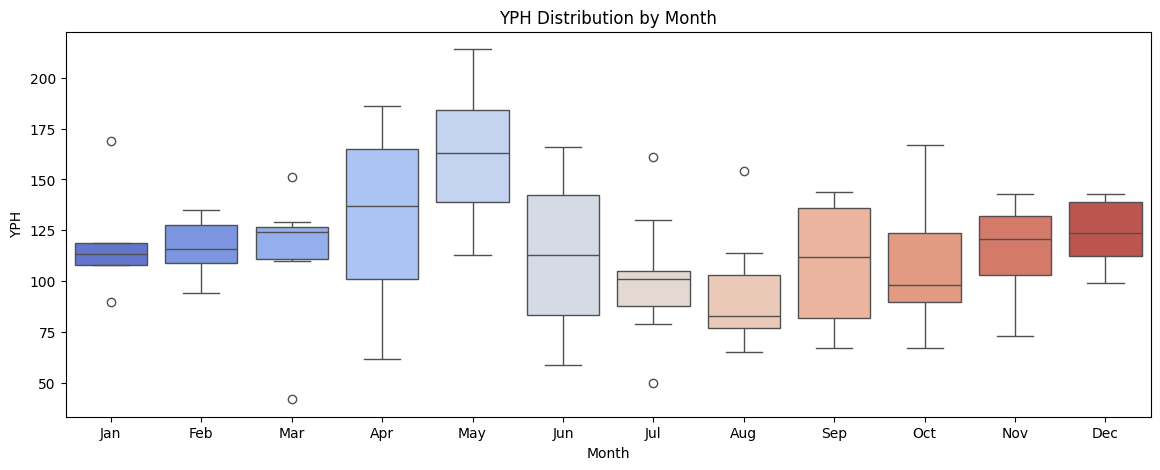

In [ ]:
plt.figure(figsize=(14,5))
sns.boxplot(data=final_data, x='Month', y='YPH', palette='coolwarm')
plt.title('YPH Distribution by Month')
plt.xlabel('Month')
plt.ylabel('YPH')
plt.show()

### **Interpretation**
1. Yearly Trend (Average YPH by Year)

      * From 2017 to 2020, YPH is relatively flat, around 100 units.
      * After 2020, there is a sharp upward trend, reaching a peak in 2023 (~142 units).
      * In 2024 and 2025, the yield slightly declines and stabilizes around 125 units.
      * Indicates a long-term improvement in yield with recent stabilization.

2. Seasonal Variation (Average YPH by Month)

    * May is the highest-yielding month, averaging about 160 units.

    * August is the lowest month, averaging under 100 units (~93).

    * Yields gradually recover from September to December.

    * Shows clear seasonal patterns, with consistent peaks and dips each year.

3. Monthly Variability (Boxplots by Month)

    * Months like April, May, June have high volatility — yields fluctuate widely.

    * January and February are very stable, with low variance.

    * Outliers exist: low values in March, high values in July.

    * Suggests some months are more predictable than others, which is important for modeling.

4. Cyclical Patterns & Extreme Spikes (Time Series)

    * Month-to-month data shows a zigzag pattern, confirming seasonal cycles.

    * Single extreme spike in early 2024 exceeds 210 units, the highest in the dataset.

    * Highlights short-term fluctuations that are not visible in yearly averages.

    * Demonstrates the importance of including temporal/lag features in models.

**Key Takeaways for Modeling**

    * Strong seasonality → include month or lag features to improve predictions.

    * High-volatility months → tree-based or robust regression models handle them better.

    * Rare extreme spikes → model needs to be robust to outliers.

    * Year trend → including year as a feature can capture long-term trends.

## Univariate Analysis (Independent Variables)

In [ ]:
# Separate numerical and categorical columns
num_cols = final_data.select_dtypes(include=['int64', 'float64']).columns
cat_cols = final_data.select_dtypes(include=['object', 'category']).columns

print("Numerical Features:")
print(list(num_cols))

print("\nCategorical Features:")
print(list(cat_cols))

Numerical Features:
['Year', 'YPH', 'T200', 'UT925', 'U709', 'Epson Salt', 'Dolomite', 'Urea', 'Zinc', 'Compost', 'BioShakthi', 'BioShield', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'relative_humidity_2m_mean', 'precipitation_sum', 'rain_sum', 'sunshine_duration', 'wind_speed_10m_max', 'wind_speed_10m_mean', 'et0_fao_evapotranspiration', 'Month_num']

Categorical Features:
['Month']


### Descriptive statistics for numerical features

In [ ]:
# Descriptive statistics for numerical features
num_summary = final_data[num_cols].describe().T
num_summary['skewness'] = final_data[num_cols].skew()

num_summary

,count,mean,std,min,25%,50%,75%,max,skewness
Year,108.0,2021.000000,2.594026,2017.000000,2019.000000,2021.000000,2.023000e+03,2.025000e+03,0.000000
YPH,108.0,141.944444,34.912396,72.000000,115.000000,142.000000,1.657500e+02,2.280000e+02,0.194769
T200,108.0,150.000000,272.063764,0.000000,0.000000,0.000000,7.500000e+01,9.000000e+02,1.436277
UT925,108.0,4499.074074,4949.681296,0.000000,0.000000,2100.000000,8.800000e+03,1.580000e+04,0.487468
U709,108.0,4863.888889,5719.951283,0.000000,0.000000,1400.000000,9.800000e+03,1.980000e+04,0.765805
Epson Salt,108.0,47.870370,92.059011,0.000000,0.000000,0.000000,2.000000e+01,3.800000e+02,1.838130
Dolomite,108.0,6263.888889,9755.290521,0.000000,0.000000,0.000000,1.350000e+04,3.700000e+04,1.298742
Urea,108.0,83.703704,127.254198,0.000000,0.000000,0.000000,1.825000e+02,3.900000e+02,1.097793
Zinc,108.0,137.129630,210.318188,0.000000,0.000000,0.000000,3.025000e+02,7.400000e+02,1.177573
Compost,108.0,33.611111,63.745380,0.000000,0.000000,0.000000,1.250000e+01,2.300000e+02,1.681402


### Histograms for fertilizer features

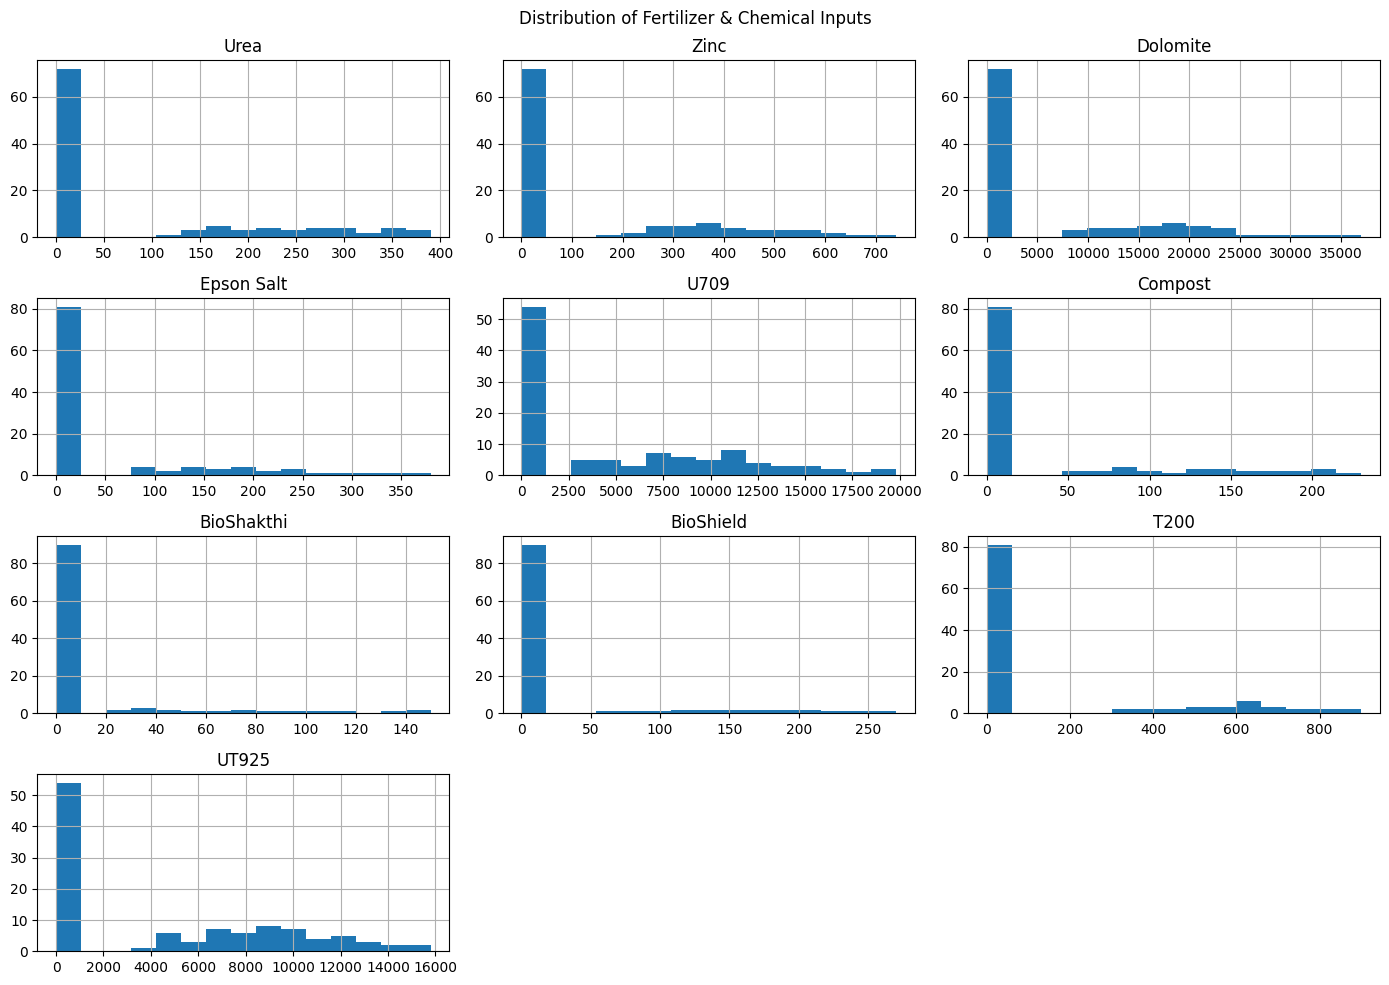

In [ ]:
fertilizer_cols = [
    'Urea', 'Zinc', 'Dolomite', 'Epson Salt',
    'U709', 'Compost', 'BioShakthi', 'BioShield','T200','UT925'
]

final_data[fertilizer_cols].hist(figsize=(14,10), bins=15)
plt.suptitle("Distribution of Fertilizer & Chemical Inputs")
plt.tight_layout()
plt.show()

### Histograms for weather features

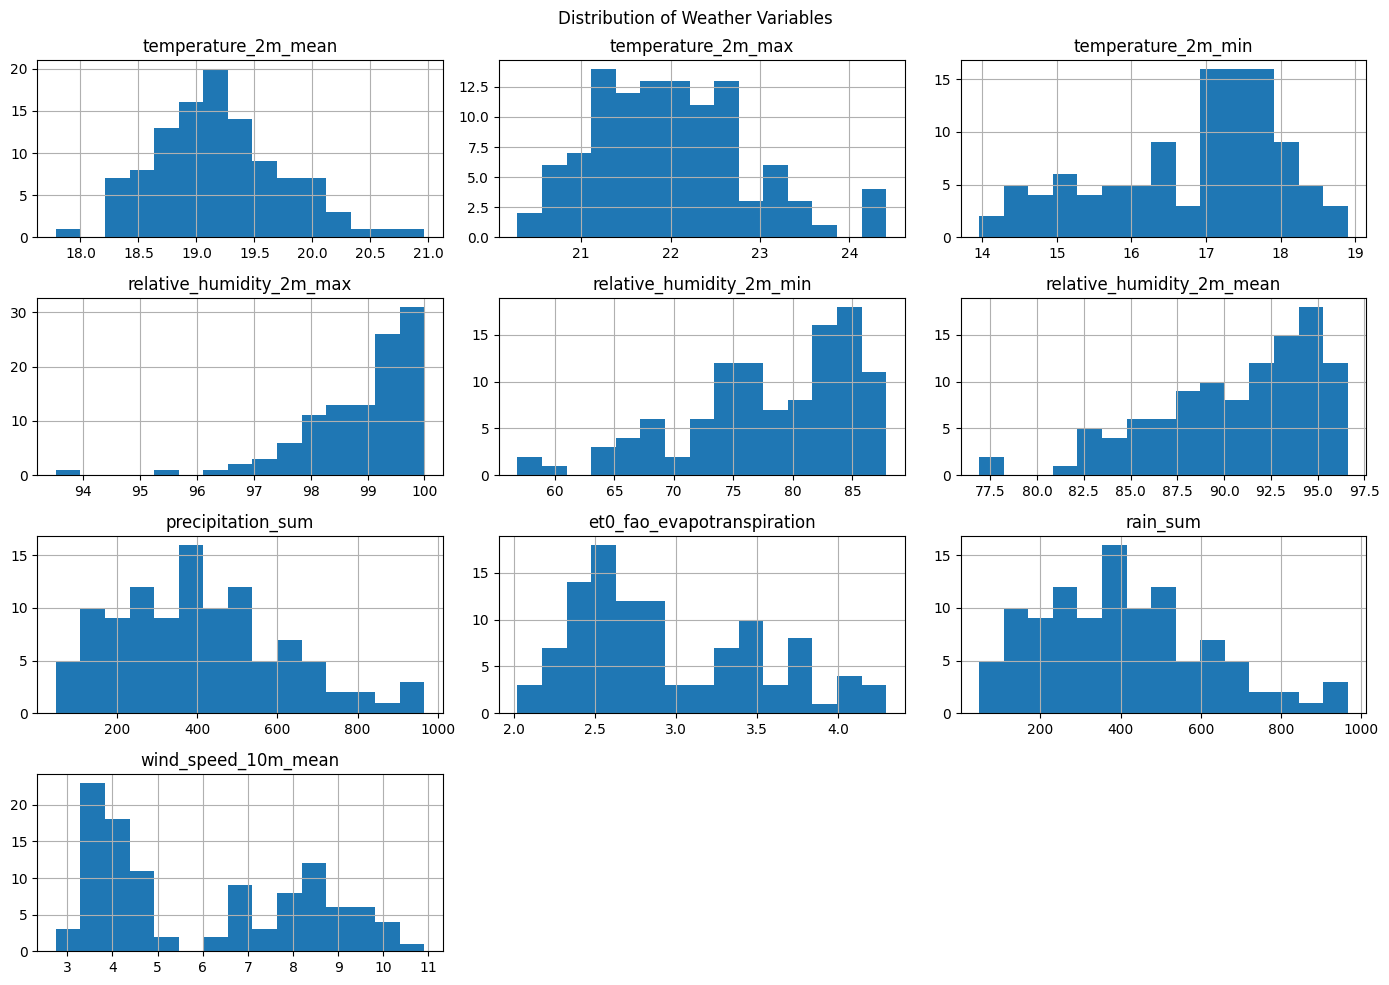

In [ ]:
weather_cols = [
    'temperature_2m_mean', 'temperature_2m_max','temperature_2m_min','relative_humidity_2m_max', 'relative_humidity_2m_min','relative_humidity_2m_mean','precipitation_sum','et0_fao_evapotranspiration',
    'rain_sum', 'wind_speed_10m_mean'
]

final_data[weather_cols].hist(figsize=(14,10), bins=15)
plt.suptitle("Distribution of Weather Variables")
plt.tight_layout()
plt.show()

### Box Plots for Numerical Columns

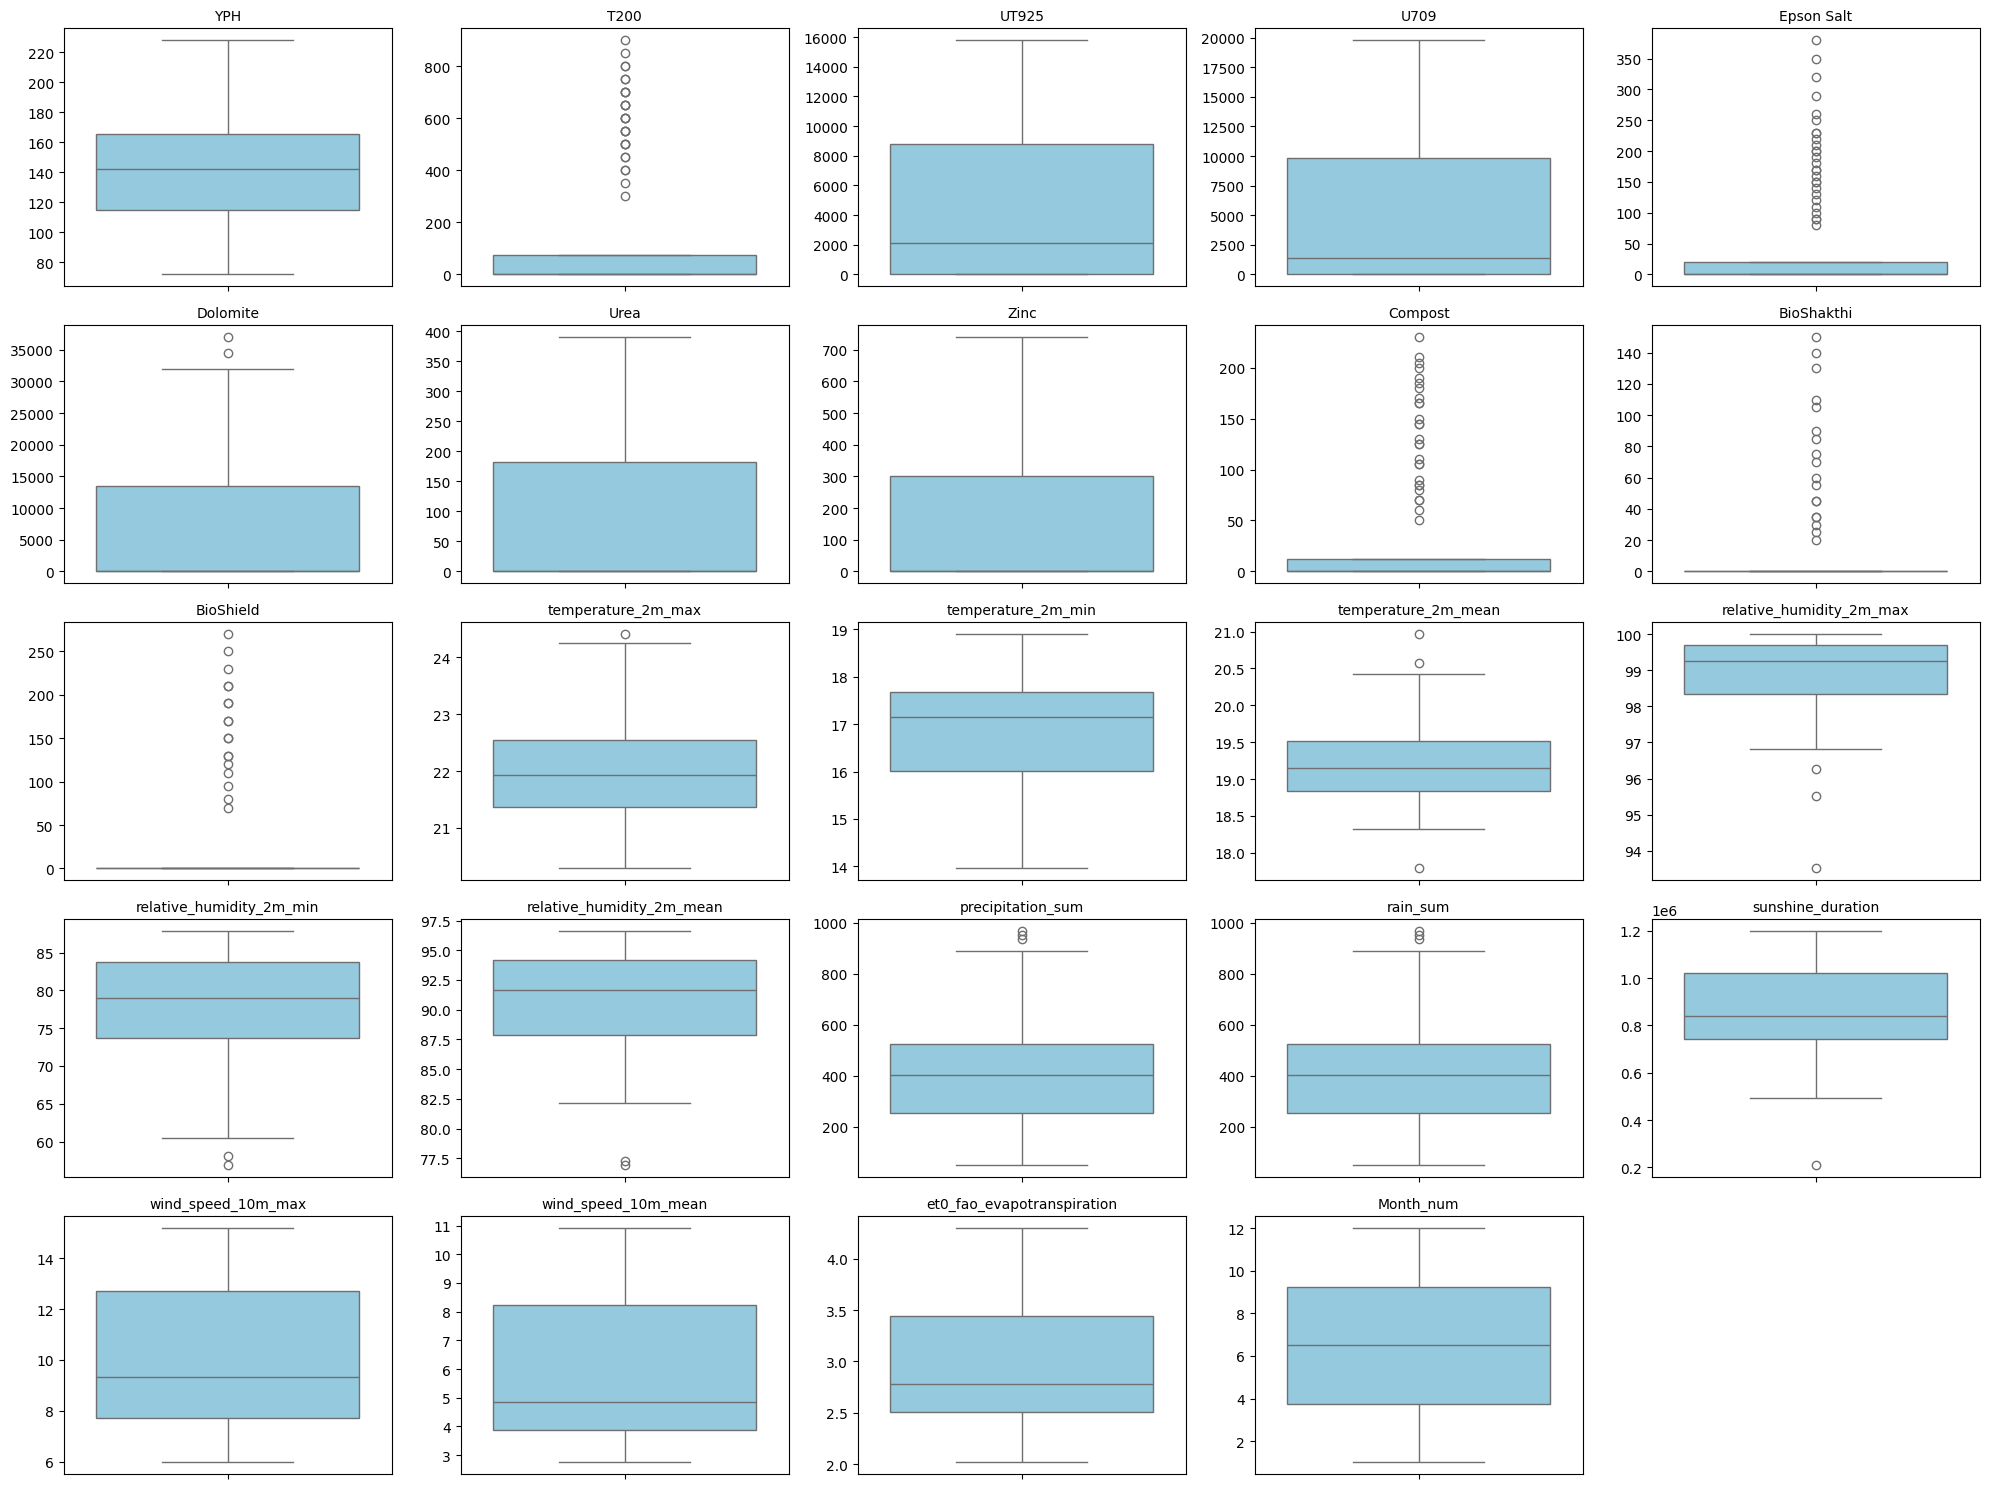

In [19]:
# Select numerical columns (exclude Year if needed)
num_cols = final_data.select_dtypes(include=['int64', 'float64']).columns
num_cols = [col for col in num_cols if col != 'Year']

cols_per_row = 5
rows = math.ceil(len(num_cols) / cols_per_row)

plt.figure(figsize=(20, rows * 3))

for i, col in enumerate(num_cols):
    plt.subplot(rows, cols_per_row, i + 1)
    sns.boxplot(y=final_data[col], color='skyblue')
    plt.title(col, fontsize=10)
    plt.ylabel("")

plt.tight_layout()
plt.show()

## Bivariate Analysis

### Scatter plots (Numerical Features vs YPH)

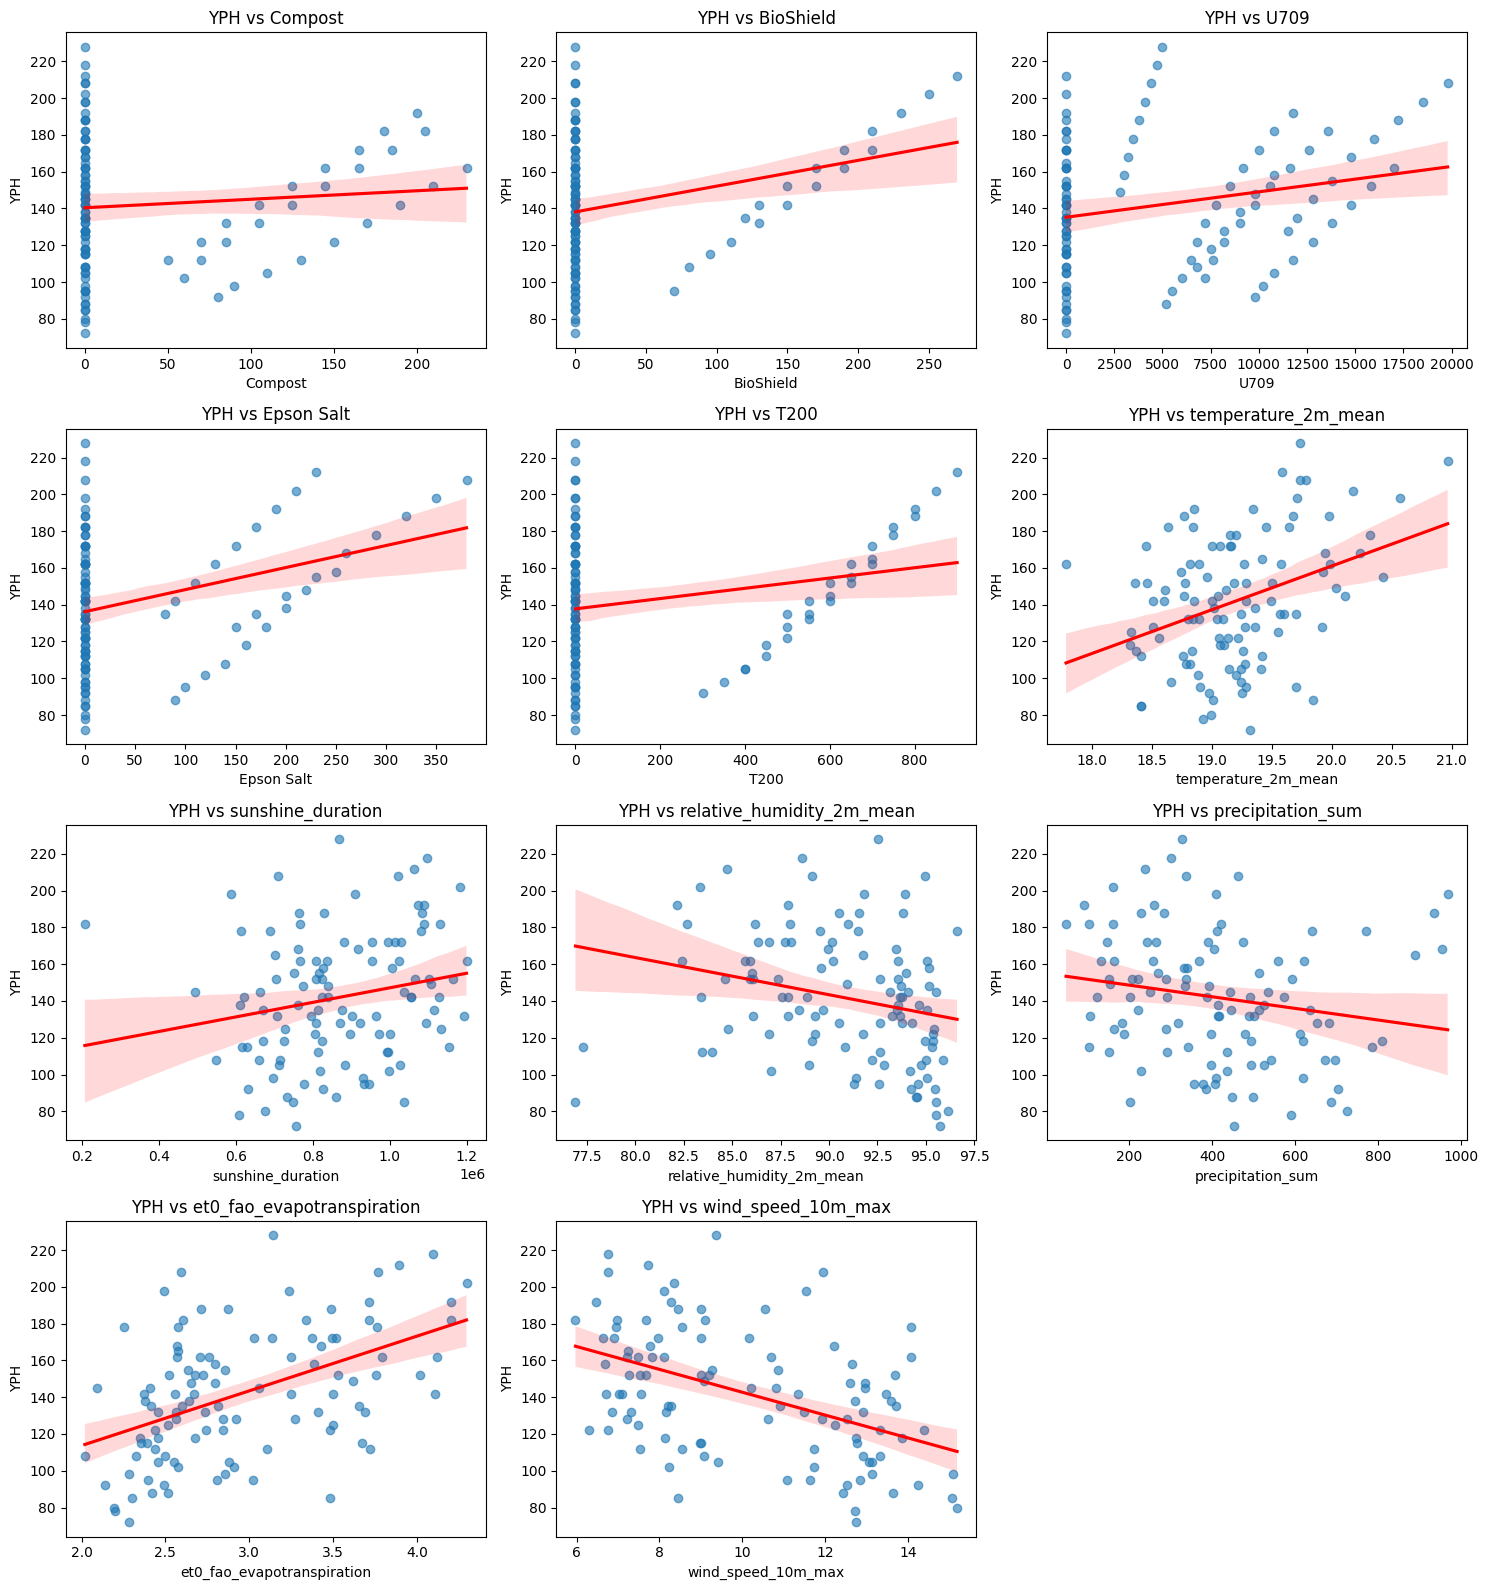

In [18]:
features = [
    'Compost',
    'BioShield',
    'U709',
    'Epson Salt',
    'T200',
    'temperature_2m_mean',
    'sunshine_duration',
    'relative_humidity_2m_mean',
    'precipitation_sum',
    'et0_fao_evapotranspiration',
    'wind_speed_10m_max'
]

cols_per_row = 3
rows = (len(features) + cols_per_row - 1) // cols_per_row

plt.figure(figsize=(15, rows * 4))

for i, col in enumerate(features):
    plt.subplot(rows, cols_per_row, i + 1)
    sns.regplot(
        x=final_data[col],
        y=final_data['YPH'],
        scatter_kws={'alpha': 0.6},
        line_kws={'color': 'red'}
    )
    plt.title(f"YPH vs {col}")
    plt.xlabel(col)
    plt.ylabel("YPH")

plt.tight_layout()
plt.show()

## Multivariate Analysis

### Correlation Matrix

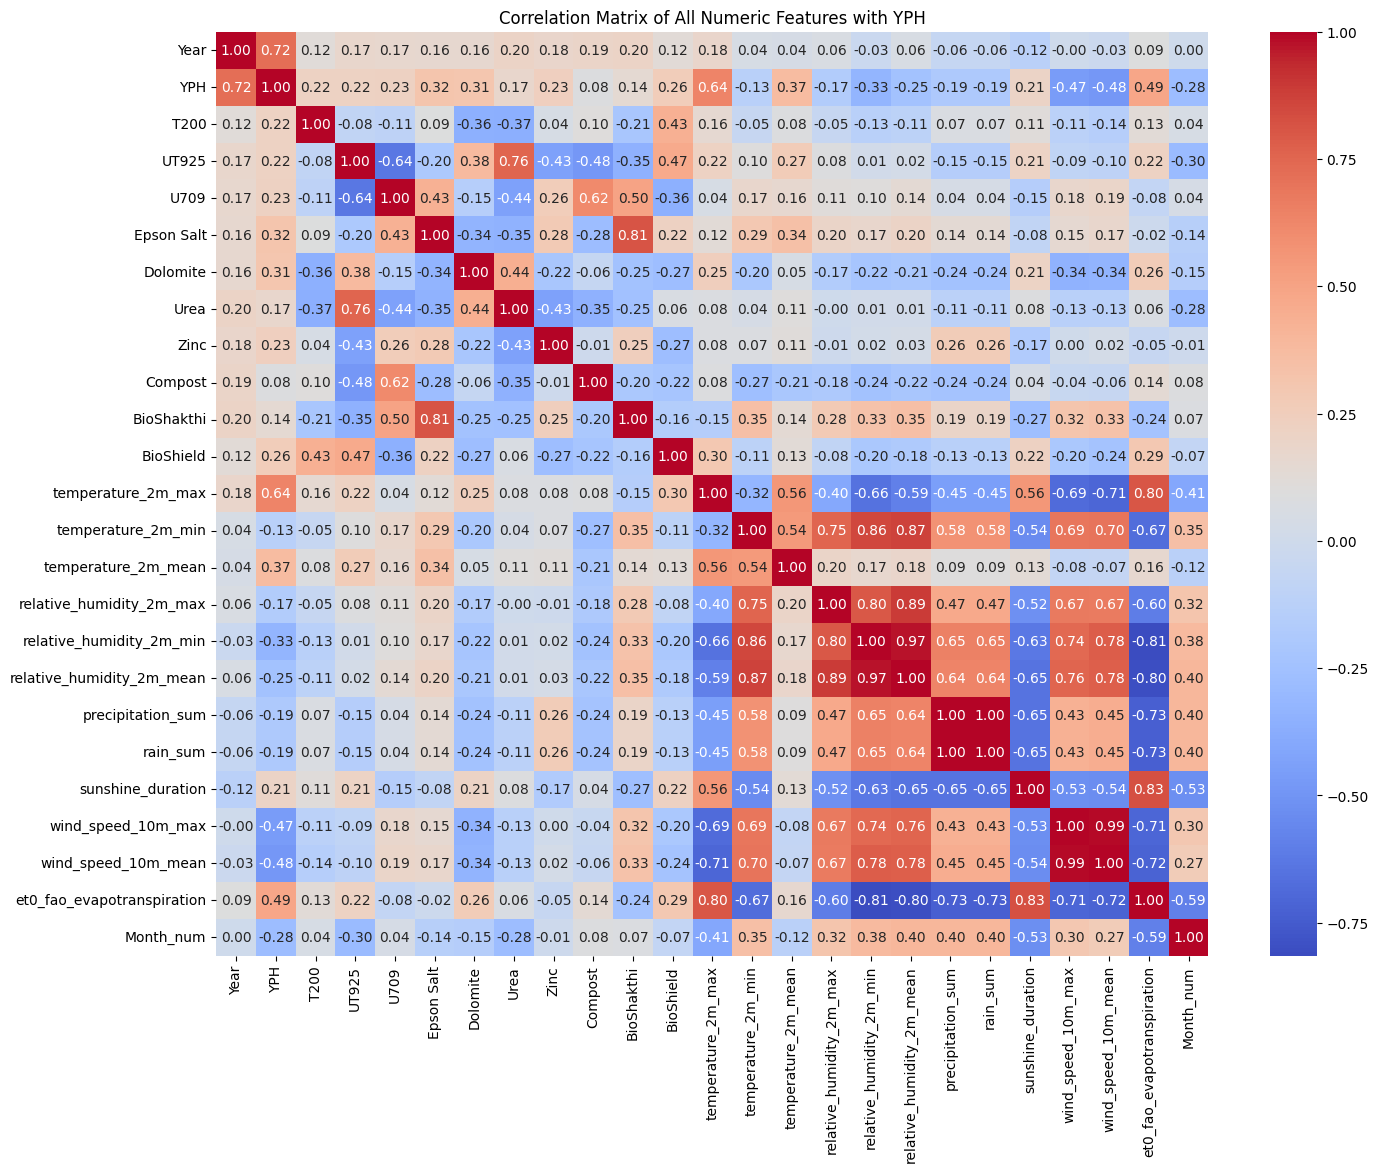

In [ ]:
# Create a numeric month column
month_map = {'Jan':1, 'Feb':2, 'Mar':3, 'Apr':4, 'May':5, 'Jun':6,
             'Jul':7, 'Aug':8, 'Sep':9, 'Oct':10, 'Nov':11, 'Dec':12}

final_data['Month_num'] = final_data['Month'].map(month_map)

# Compute correlation using numeric columns only
numeric_cols = final_data.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = final_data[numeric_cols].corr()

plt.figure(figsize=(16,12))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Correlation Matrix of All Numeric Features with YPH")
plt.show()

### Correlation of Features Specifically with YPH

In [ ]:
# Sort correlation of all features with YPH
yp_corr = corr_matrix['YPH'].sort_values(ascending=False)
print("=== Features Most Positively Correlated with YPH ===")
print(yp_corr.head(10))
print("\n=== Features Most Negatively Correlated with YPH ===")
print(yp_corr.tail(10))

=== Features Most Positively Correlated with YPH ===
YPH                           1.000000
Year                          0.719688
temperature_2m_max            0.637081
et0_fao_evapotranspiration    0.486404
temperature_2m_mean           0.370198
Epson Salt                    0.316568
Dolomite                      0.305473
BioShield                     0.261059
Zinc                          0.234886
U709                          0.226300
Name: YPH, dtype: float64

=== Features Most Negatively Correlated with YPH ===
Compost                      0.084289
temperature_2m_min          -0.133423
relative_humidity_2m_max    -0.165312
rain_sum                    -0.185516
precipitation_sum           -0.185516
relative_humidity_2m_mean   -0.246536
Month_num                   -0.278565
relative_humidity_2m_min    -0.326240
wind_speed_10m_max          -0.467037
wind_speed_10m_mean         -0.484366
Name: YPH, dtype: float64
